### Term Project Milestone 1: National Database of Childcare Prices
The goal is to understand the dataset, identify interesting patterns, and create early visuals that can support a final data story about childcare affordability and its impact on working families.

Dataset: National Database of Childcare Prices


Submitted by: Vinay Krishnan Thalappath

In [15]:
# Import libraries
from pathlib import Path
import zipfile
import re
import html
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [16]:
df = pd.read_excel("nationaldatabaseofchildcareprices.xlsx")
df.head()


,State_Name,State_Abbreviation,County_Name,County_FIPS_Code,StudyYear,UNR_16,FUNR_16,MUNR_16,UNR_20to64,FUNR_20to64,...,MFCCToddler,MFCCToddler_flag,MFCCPreschool,MFCCPreschool_flag,_75FCCInfant,_75FCCInfant_flag,_75FCCToddler,_75FCCToddler_flag,_75FCCPreschool,_75FCCPreschool_flag
0,Alabama,AL,Autauga County,1001,2008,5.42,4.41,6.32,4.6,3.5,...,83.45,3.0,81.40,1.0,97.4,1.0,97.4,3.0,95.0,1.0
1,Alabama,AL,Autauga County,1001,2009,5.93,5.72,6.11,4.8,4.6,...,87.39,3.0,85.68,1.0,102.0,1.0,102.0,3.0,100.0,1.0
2,Alabama,AL,Autauga County,1001,2010,6.21,5.57,6.78,5.1,4.6,...,91.33,3.0,89.96,1.0,106.6,1.0,106.6,3.0,105.0,1.0
3,Alabama,AL,Autauga County,1001,2011,7.55,8.13,7.03,6.2,6.3,...,95.28,3.0,94.25,1.0,111.2,1.0,111.2,3.0,110.0,1.0
4,Alabama,AL,Autauga County,1001,2012,8.60,8.88,8.29,6.7,6.4,...,99.22,3.0,98.53,1.0,115.8,1.0,115.8,3.0,115.0,1.0


In [17]:
df.shape

(34567, 227)

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34567 entries, 0 to 34566
Columns: 227 entries, State_Name to _75FCCPreschool_flag
dtypes: float64(159), int64(65), object(3)
memory usage: 59.9+ MB


In [19]:
df.columns

Index(['State_Name', 'State_Abbreviation', 'County_Name', 'County_FIPS_Code',
       'StudyYear', 'UNR_16', 'FUNR_16', 'MUNR_16', 'UNR_20to64',
       'FUNR_20to64',
       ...
       'MFCCToddler', 'MFCCToddler_flag', 'MFCCPreschool',
       'MFCCPreschool_flag', '_75FCCInfant', '_75FCCInfant_flag',
       '_75FCCToddler', '_75FCCToddler_flag', '_75FCCPreschool',
       '_75FCCPreschool_flag'],
      dtype='object', length=227)

In [20]:
df.tail()

,State_Name,State_Abbreviation,County_Name,County_FIPS_Code,StudyYear,UNR_16,FUNR_16,MUNR_16,UNR_20to64,FUNR_20to64,...,MFCCToddler,MFCCToddler_flag,MFCCPreschool,MFCCPreschool_flag,_75FCCInfant,_75FCCInfant_flag,_75FCCToddler,_75FCCToddler_flag,_75FCCPreschool,_75FCCPreschool_flag
34562,Wyoming,WY,Weston County,56045,2014,3.60,5.36,2.28,2.4,4.8,...,110.71,1.0,111.47,1.0,129.22,3.0,129.22,1.0,130.11,1.0
34563,Wyoming,WY,Weston County,56045,2015,5.16,7.86,3.16,4.2,7.6,...,110.89,1.0,110.89,1.0,129.43,1.0,129.43,1.0,129.43,1.0
34564,Wyoming,WY,Weston County,56045,2016,3.61,4.67,2.79,3.4,4.5,...,111.07,1.0,110.31,1.0,133.17,3.0,129.64,1.0,128.75,1.0
34565,Wyoming,WY,Weston County,56045,2017,2.24,2.64,1.95,2.3,2.8,...,111.26,1.0,109.74,1.0,136.91,3.0,129.85,1.0,128.08,1.0
34566,Wyoming,WY,Weston County,56045,2018,3.54,2.86,4.04,3.7,2.8,...,111.44,1.0,109.16,1.0,140.64,3.0,130.06,1.0,127.40,1.0


In [21]:
df['StudyYear'].head()

0    2008
1    2009
2    2010
3    2011
4    2012
Name: StudyYear, dtype: int64

In [22]:
df['StudyYear'].tail()

34562    2014
34563    2015
34564    2016
34565    2017
34566    2018
Name: StudyYear, dtype: int64

In [23]:
# Sort by StudyYear
df_sorted = df.sort_values(by='StudyYear')

# Show first few rows
df_sorted.head()



,State_Name,State_Abbreviation,County_Name,County_FIPS_Code,StudyYear,UNR_16,FUNR_16,MUNR_16,UNR_20to64,FUNR_20to64,...,MFCCToddler,MFCCToddler_flag,MFCCPreschool,MFCCPreschool_flag,_75FCCInfant,_75FCCInfant_flag,_75FCCToddler,_75FCCToddler_flag,_75FCCPreschool,_75FCCPreschool_flag
0,Alabama,AL,Autauga County,1001,2008,5.42,4.41,6.32,4.60,3.50,...,83.45,3.0,81.40,1.0,97.40,1.0,97.40,3.0,95.00,1.0
23561,Oklahoma,OK,Choctaw County,40023,2008,10.55,9.33,11.70,8.99,8.25,...,70.41,1.0,70.41,3.0,79.37,1.0,70.41,1.0,70.41,3.0
5499,Georgia,GA,Pike County,13231,2008,6.05,5.19,6.66,4.72,4.75,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
23572,Oklahoma,OK,Cimarron County,40025,2008,2.08,4.49,0.27,2.15,4.91,...,74.17,1.0,74.17,3.0,83.61,1.0,74.17,1.0,74.17,3.0
23583,Oklahoma,OK,Cleveland County,40027,2008,4.52,4.35,4.66,3.90,3.80,...,106.96,1.0,106.96,3.0,120.57,1.0,106.96,1.0,106.96,3.0


In [24]:
# Show last few rows
df_sorted.tail()

,State_Name,State_Abbreviation,County_Name,County_FIPS_Code,StudyYear,UNR_16,FUNR_16,MUNR_16,UNR_20to64,FUNR_20to64,...,MFCCToddler,MFCCToddler_flag,MFCCPreschool,MFCCPreschool_flag,_75FCCInfant,_75FCCInfant_flag,_75FCCToddler,_75FCCToddler_flag,_75FCCPreschool,_75FCCPreschool_flag
25023,Pennsylvania,PA,Huntingdon County,42061,2018,6.30,7.06,5.59,5.7,6.0,...,100.00,1.0,100.00,1.0,128.75,1.0,128.75,1.0,128.75,1.0
25012,Pennsylvania,PA,Greene County,42059,2018,4.42,4.76,4.13,3.8,4.0,...,160.00,1.0,160.00,1.0,172.50,1.0,172.50,1.0,172.50,1.0
4783,Georgia,GA,Douglas County,13097,2018,6.87,7.28,6.46,6.1,6.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25067,Pennsylvania,PA,Lackawanna County,42069,2018,4.77,4.43,5.08,4.6,4.3,...,167.50,1.0,150.00,1.0,175.00,1.0,176.25,1.0,175.00,1.0
34566,Wyoming,WY,Weston County,56045,2018,3.54,2.86,4.04,3.7,2.8,...,111.44,1.0,109.16,1.0,140.64,3.0,130.06,1.0,127.40,1.0


>>This database provides county-level childcare prices for most states in the United States in 10 years. The National Database of Childcare Prices (NDCP) is the most comprehensive federal source of childcare prices at the county level. The database offers childcare price data by childcare provider type, age of children, and county characteristics. Data are available from 2008 through 2022. source:https://dataportal.dol.gov/datasets/10278
>>
>>some of the abbreviations are,
>>
>>
>>state_name	--Name of state for which the data are being entered.
>>
>>state_abbreviation	--Two-letter state abbreviation
>>
>>county_name	--Name of the county for which data are being entered.
>>
>>mcbto5	--Weekly, full-time median price charged for Center-Based Care for those aged 0 to 5 months based on the results reported in the market rate survey report for the county or the rate zone/cluster to which the county is assigned
>>
>>mc6to11	--Weekly, full-time median price charged for Center-Based Care for those aged 6 to 11 months based on the results reported in the market rate survey report for the county or the rate zone/cluster to which the county is assigned
>>
>>mc12to17	--Weekly, full-time median price charged for Center-Based Care for those aged 12 to 17 months based on the results reported in the market rate survey report for the county or the rate zone/cluster to which the county is assigned
>>
>>mc18to23	--Weekly, full-time median price charged for Center-Based Care for those aged 18 to 23 months based on the results reported in the market rate survey report for the county or the rate zone/cluster to which the county is assigned
>>
>>mc24to29	--Weekly, full-time median price charged for Center-Based Care for those aged 24 to 29 months based on the results reported in the market rate survey report for the county or the rate zone/cluster to which the county is assigned
>>
>>mc30to35	--Weekly, full-time median price charged for Center-Based Care for those aged 30 to 35 months based on the results reported in the market rate survey report for the county or the rate zone/cluster to which the county is assigned
>>
>>mc36to41	--Weekly, full-time median price charged for Center-Based Care for those aged 36 to 41 months based on the results reported in the market rate survey report for the county or the rate zone/cluster to which the county is assigned
>>
>>mc42to47	--Weekly, full-time median price charged for Center-Based Care for those aged 42 to 47 months based on the results reported in the market rate survey report for the county or the rate zone/cluster to which the county is assigned
>>
>>mc48to53	--Weekly, full-time median price charged for Center-Based Care for those aged 48 to 53 months based on the results reported in the market rate survey report for the county or the rate zone/cluster to which the county is assigned
>>
>>mc54tosa	--Weekly, full-time median price charged for Center-Based Care for those aged 54 months to school age based on the results reported in the market rate survey report for the county or the rate zone/cluster to which the county is assigned
>>
>>mcsa	--Weekly, full-time median price charged for Center-Based Care for those who are school age based on the results reported in the market rate survey report for the county or the rate zone/cluster to which the county is assigned
>>
>>mfccbto5	--Weekly, full-time median price charged for Family Childcare for those aged 0 to 5 months based on the results reported in the market rate survey report for the county or the rate zone/cluster to which the county is assigned
>>
>>mfcc6to11	--Weekly, full-time median price charged for Family Childcare for those aged 6 to 11 months based on the results reported in the market rate survey report for the county or the rate zone/cluster to which the county is assigned
>>
>>mfcc12to17	--Weekly, full-time median price charged for Family Childcare for those aged 12 to 17 months based on the results reported in the market rate survey report for the county or the rate zone/cluster to which the county is assigned
>>
>>mfcc18to23	--Weekly, full-time median price charged for Family Childcare for those aged 18 to 23 months based on the results reported in the market rate survey report for the county or the rate zone/cluster to which the county is assigned.
>>
>>mfcc24to29	--Weekly, full-time median price charged for Family Childcare for those aged 24 to 29 months based on the results reported in the market rate survey report for the county or the rate zone/cluster to which the county is assigned	
mfcc30to35--	Weekly, full-time median price charged for Family Childcare for those aged 30 to 35 months based on the results reported in the market rate survey report for the county or the rate zone/cluster to which the county is assigned
>>
>>mfcc36to41--	Weekly, full-time median price charged for Family Childcare for those aged 36 to 41 months based on the results reported in the market rate survey report for the county or the rate zone/cluster to which the county is assigned
>>
>>mfcc42to47--	Weekly, full-time median price charged for Family Childcare for those aged 42 to 47 months based on the results reported in the market rate survey report for the county or the rate zone/cluster to which the county is assigned
>>
>>mfcc48to53	--Weekly, full-time median price charged for Family Childcare for those aged 48 to 53 months based on the results reported in the market rate survey report for the county or the rate zone/cluster to which the county is assigned
>>
>>mfcc54tosa--	Weekly, full-time median price charged for Family Childcare for those aged 54 months to school age based on the results reported in the market rate survey report or the county or the rate zone/cluster to which the county is assigned	
mfccsa	--Weekly, full-time median price charged for Family Childcare for those who are school age based on the results reported in the market rate survey report for the county or the rate zone/cluster to which the county is assigned
>>
>>pr_f	--Poverty rate for families
>>
>>pr_p	--Poverty rate for individuals
>>
>>mhi	--Median household income (i.e. 50th percentile)
>>
>>mfi	--Median family income   (i.e. 50th percentile)




In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34567 entries, 0 to 34566
Columns: 227 entries, State_Name to _75FCCPreschool_flag
dtypes: float64(159), int64(65), object(3)
memory usage: 59.9+ MB


##### It is important to note that this dataset is large with 227 columns ranging 34567 rows and contains many features related to childcare prices, household income, employment, population, poverty, and county-level geography. Since we are still studying the meaning of the different fields and how they relate to each other, this milestone focuses on an initial exploration.

##### At this stage, the visuals are meant to provide a simple starting point. They help show patterns in the data and make it easier to decide what should be analyzed more deeply in the next phase. 



In [26]:
#we will take  a few columns and analyze

important_cols = [
    "State_Name", "State_Abbreviation", "County_Name", "County_FIPS_Code", "StudyYear",
    "MHI", "MHI_2018",
    "MCInfant", "MCToddler", "MCPreschool",
    "MFCCInfant", "MFCCToddler", "MFCCPreschool",
    "_75CInfant", "_75CToddler", "_75CPreschool",
    "_75FCCInfant", "_75FCCToddler", "_75FCCPreschool"
]

childcare = df[important_cols].copy()

# Convert selected numeric columns safely
numeric_cols = [c for c in childcare.columns if c not in ["State_Name", "State_Abbreviation", "County_Name"]]
for col in numeric_cols:
    childcare[col] = pd.to_numeric(childcare[col], errors="coerce")

latest_year = int(childcare["StudyYear"].max())
latest = childcare[childcare["StudyYear"] == latest_year].copy()

print("Latest year:", latest_year)
print("Latest-year rows:", latest.shape[0])
childcare.head()

Latest year: 2018
Latest-year rows: 3142


,State_Name,State_Abbreviation,County_Name,County_FIPS_Code,StudyYear,MHI,MHI_2018,MCInfant,MCToddler,MCPreschool,MFCCInfant,MFCCToddler,MFCCPreschool,_75CInfant,_75CToddler,_75CPreschool,_75FCCInfant,_75FCCToddler,_75FCCPreschool
0,Alabama,AL,Autauga County,1001,2008,50837.0,58462.55,104.95,104.95,85.92,83.45,83.45,81.40,125.8,125.8,103.0,97.4,97.4,95.0
1,Alabama,AL,Autauga County,1001,2009,51463.0,60211.71,105.11,105.11,87.59,87.39,87.39,85.68,126.0,126.0,105.0,102.0,102.0,100.0
2,Alabama,AL,Autauga County,1001,2010,53255.0,61775.80,105.28,105.28,89.26,91.33,91.33,89.96,126.2,126.2,107.0,106.6,106.6,105.0
3,Alabama,AL,Autauga County,1001,2011,53899.0,60366.88,105.45,105.45,90.93,95.28,95.28,94.25,126.4,126.4,109.0,111.2,111.2,110.0
4,Alabama,AL,Autauga County,1001,2012,53773.0,59150.30,105.61,105.61,92.60,99.22,99.22,98.53,126.6,126.6,111.0,115.8,115.8,115.0


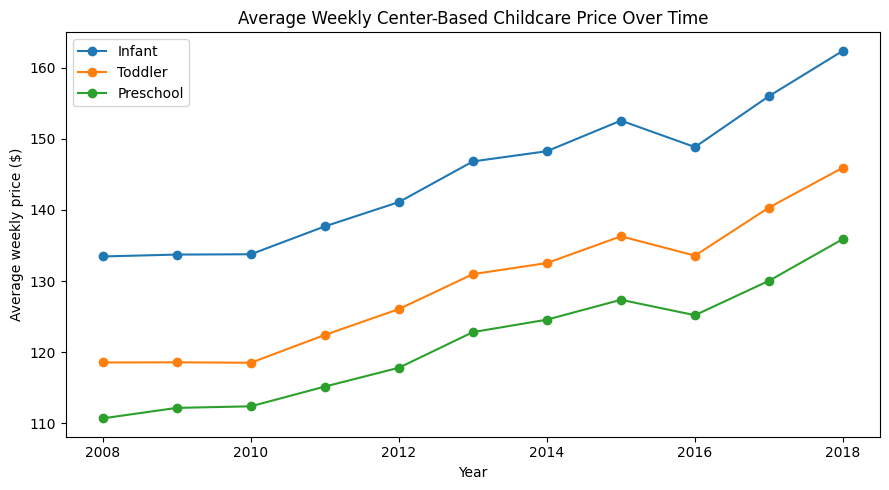

,StudyYear,MCInfant,MCToddler,MCPreschool
0,2008,133.468153,118.560344,110.708076
1,2009,133.731468,118.585008,112.177964
2,2010,133.776198,118.522913,112.397936
3,2011,137.697239,122.436360,115.175894
4,2012,141.111193,126.067608,117.818909
5,2013,146.826673,130.981225,122.830535
6,2014,148.265372,132.538480,124.581941
7,2015,152.569370,136.301126,127.373211
8,2016,148.844642,133.585585,125.209326
9,2017,156.005874,140.343896,130.048227


In [27]:
# National average weekly center-based childcare price over time
national_yearly = childcare.groupby("StudyYear")[["MCInfant", "MCToddler", "MCPreschool"]].mean().reset_index()

plt.figure(figsize=(9, 5))
plt.plot(national_yearly["StudyYear"], national_yearly["MCInfant"], marker="o", label="Infant")
plt.plot(national_yearly["StudyYear"], national_yearly["MCToddler"], marker="o", label="Toddler")
plt.plot(national_yearly["StudyYear"], national_yearly["MCPreschool"], marker="o", label="Preschool")
plt.title("Average Weekly Center-Based Childcare Price Over Time")
plt.xlabel("Year")
plt.ylabel("Average weekly price ($)")
plt.legend()
plt.tight_layout()
#plt.savefig(os.path.join(chart_dir, "visual_2_price_trend_by_age.png"), dpi=300)
plt.show()

national_yearly


>>Childcare prices increased from 2008 to 2018 for infants, toddlers, and preschoolers. Infant care was consistently the most expensive, which suggests that families with very young children face the greatest childcare cost burden.

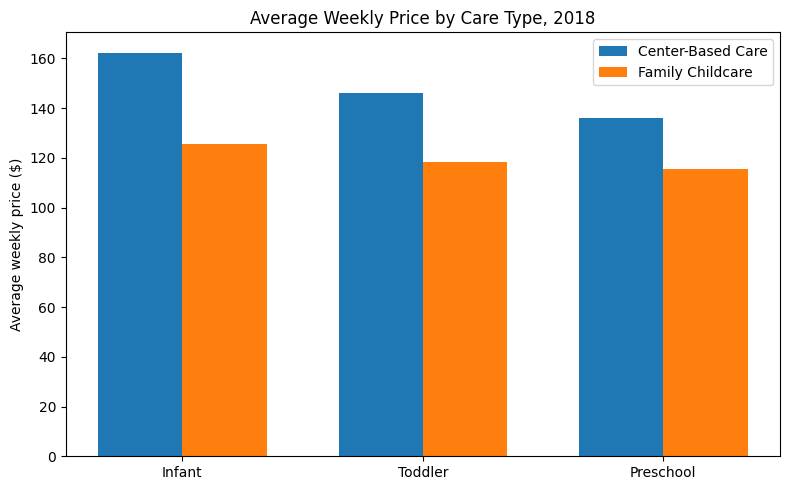

,Age Group,Center-Based Care,Family Childcare
0,Infant,162.392076,125.615094
1,Toddler,145.958242,118.510217
2,Preschool,135.920983,115.353062


In [28]:
#Center-based care vs family childcare in the latest year
latest_avg = latest[["MCInfant", "MCToddler", "MCPreschool", "MFCCInfant", "MFCCToddler", "MFCCPreschool"]].mean()
comparison = pd.DataFrame({
    "Age Group": ["Infant", "Toddler", "Preschool"],
    "Center-Based Care": [latest_avg["MCInfant"], latest_avg["MCToddler"], latest_avg["MCPreschool"]],
    "Family Childcare": [latest_avg["MFCCInfant"], latest_avg["MFCCToddler"], latest_avg["MFCCPreschool"]]
})

x = range(len(comparison))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar([i - width/2 for i in x], comparison["Center-Based Care"], width=width, label="Center-Based Care")
plt.bar([i + width/2 for i in x], comparison["Family Childcare"], width=width, label="Family Childcare")
plt.xticks(list(x), comparison["Age Group"])
plt.title(f"Average Weekly Price by Care Type, {latest_year}")
plt.ylabel("Average weekly price ($)")
plt.legend()
plt.tight_layout()
#plt.savefig(os.path.join(chart_dir, "visual_3_center_vs_family_childcare.png"), dpi=300)
plt.show()

comparison


>>In 2018, center-based care was more expensive than family childcare for every age group. Infant care had the highest weekly price, showing that families with younger children face the greatest childcare cost pressure.

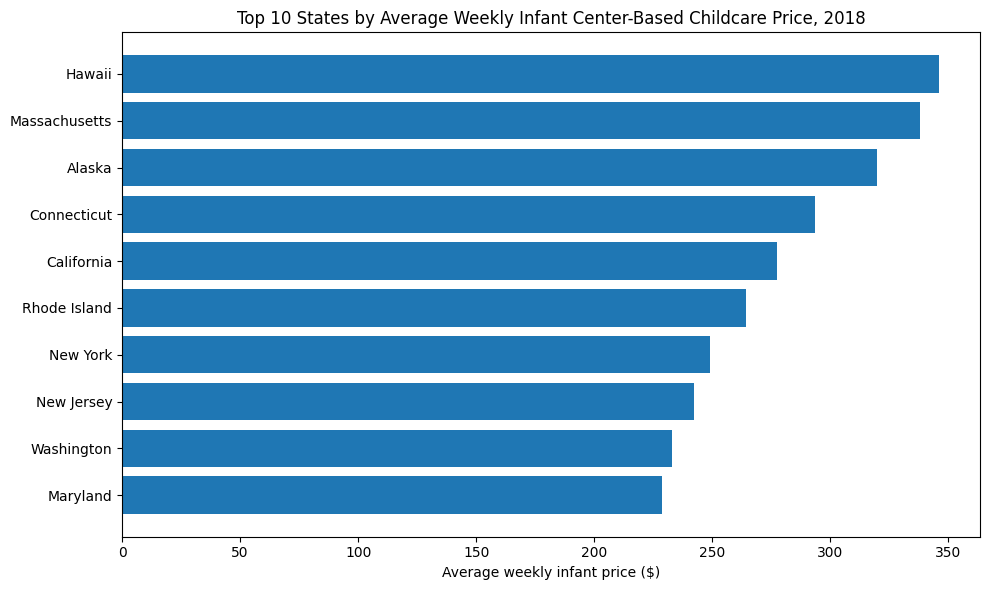

,State_Name,MCInfant,MCToddler,MCPreschool,MHI
11,Hawaii,346.150000,346.150000,226.150000,71935.400000
21,Massachusetts,338.142857,310.332143,242.628571,74596.285714
1,Alaska,319.814286,277.038571,229.235714,67802.482759
6,Connecticut,293.375000,293.375000,241.125000,77068.875000
4,California,277.348793,198.593966,198.593966,64378.551724
39,Rhode Island,264.416000,252.546000,226.646000,71914.400000
32,New York,249.280645,228.404839,213.960323,60464.596774
30,New Jersey,242.212857,220.355714,192.927619,79847.714286
47,Washington,233.018974,202.327179,181.934359,56904.384615
20,Maryland,228.526667,163.562083,163.562083,74890.708333


In [29]:
#Top 10 states by average infant center-based childcare price in latest year
state_summary = latest.groupby("State_Name")[["MCInfant", "MCToddler", "MCPreschool", "MHI"]].mean().reset_index()
top10_infant = state_summary.sort_values("MCInfant", ascending=False).head(10)

plt.figure(figsize=(10, 6))
plt.barh(top10_infant["State_Name"], top10_infant["MCInfant"])
plt.gca().invert_yaxis()
plt.title(f"Top 10 States by Average Weekly Infant Center-Based Childcare Price, {latest_year}")
plt.xlabel("Average weekly infant price ($)")
plt.tight_layout()
#plt.savefig(os.path.join(chart_dir, "visual_4_top10_states_infant_price.png"), dpi=300)
plt.show()

top10_infant


>>In 2018, Hawaii, Massachusetts, and Alaska had the highest average weekly infant center-based childcare prices. This shows that childcare affordability challenges are stronger in some states than others.

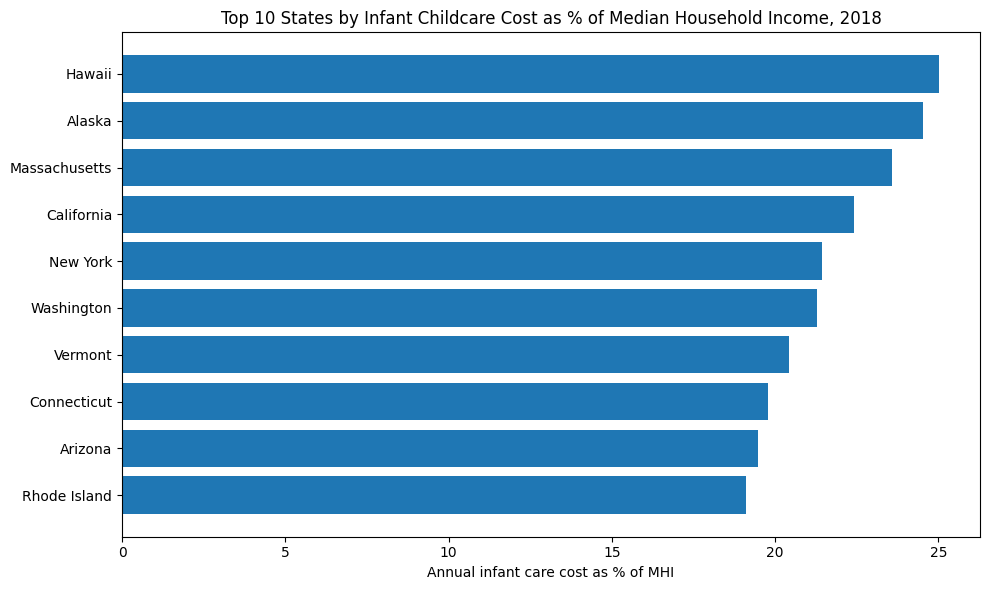

,State_Name,MCInfant,MHI,Infant_Annual_Cost,Infant_Cost_Percent_of_MHI
11,Hawaii,346.150000,71935.400000,17999.800000,25.022173
1,Alaska,319.814286,67802.482759,16630.342857,24.527631
21,Massachusetts,338.142857,74596.285714,17583.428571,23.571453
4,California,277.348793,64378.551724,14422.137241,22.402084
32,New York,249.280645,60464.596774,12962.593548,21.438320
47,Washington,233.018974,56904.384615,12116.986667,21.293591
45,Vermont,226.985714,57767.500000,11803.257143,20.432349
6,Connecticut,293.375000,77068.875000,15255.500000,19.794632
2,Arizona,178.010000,47545.666667,9256.520000,19.468693
39,Rhode Island,264.416000,71914.400000,13749.632000,19.119442


In [30]:
#Annual infant care cost as a percent of median household income
# Annual cost estimate = weekly price * 52
state_summary["Infant_Annual_Cost"] = state_summary["MCInfant"] * 52
state_summary["Infant_Cost_Percent_of_MHI"] = (state_summary["Infant_Annual_Cost"] / state_summary["MHI"]) * 100

top10_affordability = state_summary.dropna(subset=["Infant_Cost_Percent_of_MHI"]).sort_values(
    "Infant_Cost_Percent_of_MHI", ascending=False
).head(10)

plt.figure(figsize=(10, 6))
plt.barh(top10_affordability["State_Name"], top10_affordability["Infant_Cost_Percent_of_MHI"])
plt.gca().invert_yaxis()
plt.title(f"Top 10 States by Infant Childcare Cost as % of Median Household Income, {latest_year}")
plt.xlabel("Annual infant care cost as % of MHI")
plt.tight_layout()
#plt.savefig(os.path.join(chart_dir, "visual_5_affordability_ratio.png"), dpi=300)
plt.show()

top10_affordability[["State_Name", "MCInfant", "MHI", "Infant_Annual_Cost", "Infant_Cost_Percent_of_MHI"]]


>>In 2018, Hawaii, Alaska, and Massachusetts had the highest infant childcare burden compared with median household income. This shows that affordability is not only about price, but also about how much families earn.

#### Average Household iNcome Vs Average Infant care cost

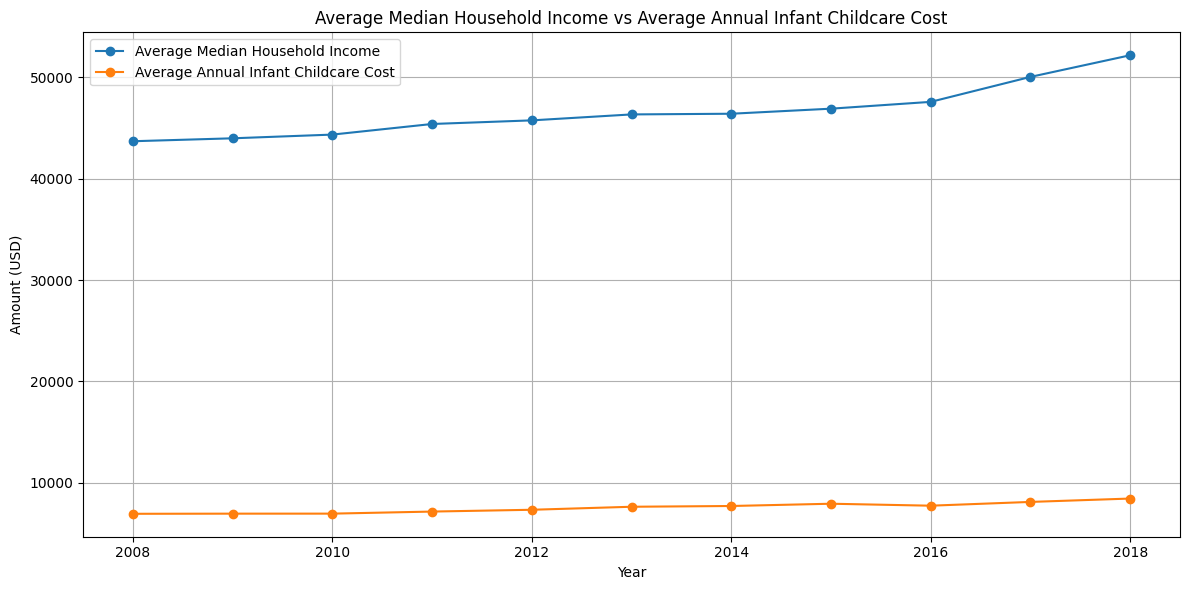

In [31]:
# Keep only needed columns
compare_df = df[["StudyYear", "MHI", "MCInfant"]].copy()

# Remove missing values
compare_df = compare_df.dropna()

# Convert weekly infant childcare price to annual cost
compare_df["Annual_Infant_Care_Cost"] = compare_df["MCInfant"] * 52

# Group by year and calculate averages
yearly_compare = compare_df.groupby("StudyYear").agg(
    Avg_Median_Household_Income=("MHI", "mean"),
    Avg_Annual_Infant_Childcare_Cost=("Annual_Infant_Care_Cost", "mean")
).reset_index()

# Calculate affordability ratio
yearly_compare["Childcare_as_%_of_Income"] = (
    yearly_compare["Avg_Annual_Infant_Childcare_Cost"] /
    yearly_compare["Avg_Median_Household_Income"]
) * 100

# Plot
plt.figure(figsize=(12, 6))
plt.plot(
    yearly_compare["StudyYear"],
    yearly_compare["Avg_Median_Household_Income"],
    marker="o",
    label="Average Median Household Income"
)
plt.plot(
    yearly_compare["StudyYear"],
    yearly_compare["Avg_Annual_Infant_Childcare_Cost"],
    marker="o",
    label="Average Annual Infant Childcare Cost"
)

plt.title("Average Median Household Income vs Average Annual Infant Childcare Cost")
plt.xlabel("Year")
plt.ylabel("Amount (USD)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


>>This chart compares average median household income with average annual infant childcare cost from 2008 to 2018. Although childcare cost is lower than total household income, it still represents a major yearly expense for families. This comparison helps show that childcare affordability is not only about the actual price of care, but also about how much of a family’s income must be used to pay for it.


The current analysis is an initial exploration of the National Database of Childcare Prices. The dataset contains many important features related to childcare prices, household income, employment, poverty, population, geography, and family structure. At this stage, we are still studying the meaning of these variables and how they relate to one another. In the coming milestones, the analysis will continue by narrowing the dataset to the most meaningful features, examining relationships between childcare cost and income, comparing differences across states and counties, and identifying which factors are most useful for explaining childcare affordability. This will help build a clearer story about how childcare prices affect families and where affordability challenges are most visible.

## Milestone -2

In [32]:
#Create a copy of the current dataset for additional analysis
analysis_df = df.copy()


In [33]:
#Create annual childcare cost estimates
# Weekly cost is multiplied by 52 to estimate yearly childcare cost
analysis_df["annual_infant_center"] = analysis_df["MCInfant"] * 52
analysis_df["annual_toddler_center"] = analysis_df["MCToddler"] * 52
analysis_df["annual_preschool_center"] = analysis_df["MCPreschool"] * 52



# Create affordability burden percentages
# These show childcare cost as a percentage of median household income

analysis_df["infant_burden_pct"] = (analysis_df["annual_infant_center"] / analysis_df["MHI"]) * 100
analysis_df["toddler_burden_pct"] = (analysis_df["annual_toddler_center"] / analysis_df["MHI"]) * 100
analysis_df["preschool_burden_pct"] = (analysis_df["annual_preschool_center"] / analysis_df["MHI"]) * 100

# Preview new columns
analysis_df[
    [
        "StudyYear",
        "State_Name",
        "County_Name",
        "MHI",
        "annual_infant_center",
        "annual_toddler_center",
        "annual_preschool_center",
        "infant_burden_pct",
        "toddler_burden_pct",
        "preschool_burden_pct"
    ]
].head()

,StudyYear,State_Name,County_Name,MHI,annual_infant_center,annual_toddler_center,annual_preschool_center,infant_burden_pct,toddler_burden_pct,preschool_burden_pct
0,2008,Alabama,Autauga County,50837.0,5457.40,5457.40,4467.84,10.735095,10.735095,8.788560
1,2009,Alabama,Autauga County,51463.0,5465.72,5465.72,4554.68,10.620679,10.620679,8.850397
2,2010,Alabama,Autauga County,53255.0,5474.56,5474.56,4641.52,10.279899,10.279899,8.715651
3,2011,Alabama,Autauga County,53899.0,5483.40,5483.40,4728.36,10.173473,10.173473,8.772630
4,2012,Alabama,Autauga County,53773.0,5491.72,5491.72,4815.20,10.212783,10.212783,8.954680


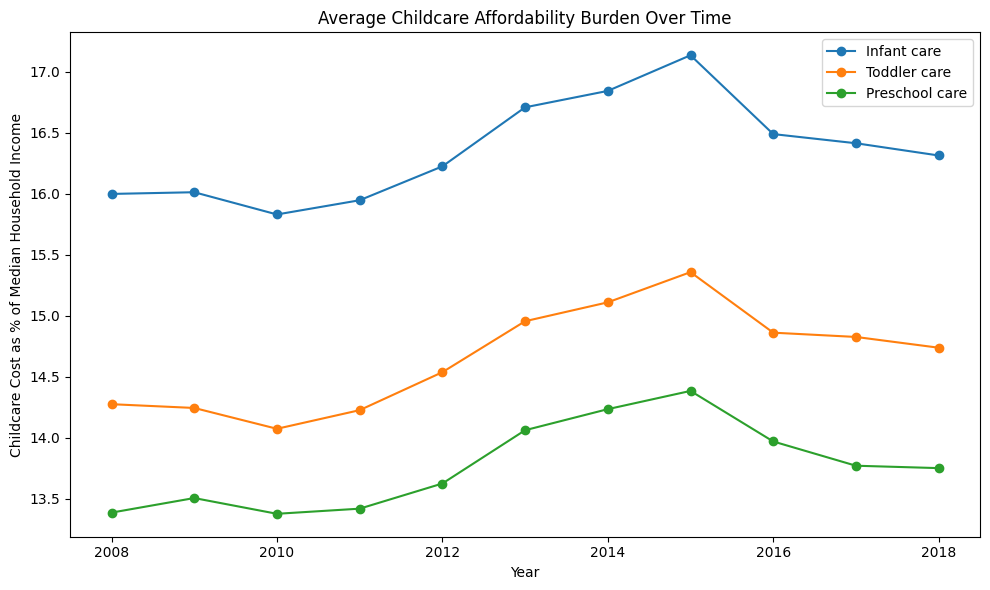

In [34]:
#Childcare burden by care type over time

# Average childcare burden by year and care type
burden_by_year = analysis_df.groupby("StudyYear")[
    ["infant_burden_pct", "toddler_burden_pct", "preschool_burden_pct"]
].mean()

plt.figure(figsize=(10, 6))
plt.plot(burden_by_year.index, burden_by_year["infant_burden_pct"], marker="o", label="Infant care")
plt.plot(burden_by_year.index, burden_by_year["toddler_burden_pct"], marker="o", label="Toddler care")
plt.plot(burden_by_year.index, burden_by_year["preschool_burden_pct"], marker="o", label="Preschool care")

plt.title("Average Childcare Affordability Burden Over Time")
plt.xlabel("Year")
plt.ylabel("Childcare Cost as % of Median Household Income")
plt.legend()
plt.tight_layout()
plt.show()

>>compares childcare affordability burden across infant, toddler, and preschool care. Infant care is expected to show the highest burden because care for younger children usually requires more staffing and resources. 

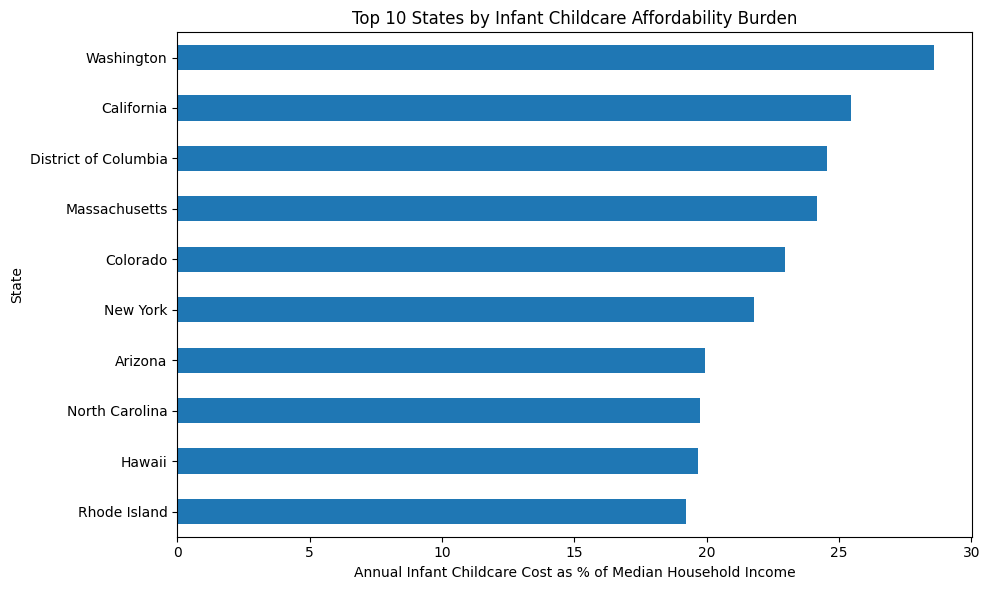

In [35]:
#Top 10 states by infant childcare burden

# Average infant childcare burden by state
state_burden = (
    analysis_df.groupby("State_Name")["infant_burden_pct"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
state_burden.sort_values().plot(kind="barh")

plt.title("Top 10 States by Infant Childcare Affordability Burden")
plt.xlabel("Annual Infant Childcare Cost as % of Median Household Income")
plt.ylabel("State")
plt.tight_layout()
plt.show()

>>Washington, California, District of Columbia, and Massachusetts show the highest infant childcare affordability burden. This means infant childcare takes a larger share of median household income in these places.

In [36]:
#important factors related to childcare burden

# Select possible explanatory variables from the dataset


possible_factors = [
    "MHI",
    "MHI_2018",
    "TotalPop",
    "Households",
    "PR_F",
    "PR_P",
    "UNR_20to64",
    "FUNR_20to64",
    "MUNR_20to64",
    "FLFPR_20to64",
    "FLFPR_20to64_Under6",
    "MLFPR_20to64",
    "MLFPR_20to64_Under6",
    "H_Under6_BothWork",
    "H_Under6_FWork",
    "H_Under6_MWork",
    "H_Under6_SingleM",
    "H_Under6_SingleF"
]

# Keep only columns that actually exist in your dataset
factor_columns = [col for col in possible_factors if col in analysis_df.columns]

print("Columns used for factor analysis:")
print(factor_columns)

# Create factor analysis dataframe
factor_df = analysis_df[factor_columns + ["infant_burden_pct"]].copy()

# Convert selected columns to numeric
for col in factor_df.columns:
    factor_df[col] = pd.to_numeric(factor_df[col], errors="coerce")

# Calculate correlation with infant childcare burden
correlations = (
    factor_df.corr(numeric_only=True)["infant_burden_pct"]
    .drop("infant_burden_pct")
    .sort_values(key=abs, ascending=False)
)

print("Factors most related to infant childcare burden:")
print(correlations)

Columns used for factor analysis:
['MHI', 'MHI_2018', 'TotalPop', 'Households', 'PR_F', 'PR_P', 'UNR_20to64', 'FUNR_20to64', 'MUNR_20to64', 'FLFPR_20to64', 'FLFPR_20to64_Under6', 'MLFPR_20to64', 'H_Under6_BothWork', 'H_Under6_FWork', 'H_Under6_MWork', 'H_Under6_SingleM']
Factors most related to infant childcare burden:
MUNR_20to64            0.342407
UNR_20to64             0.317651
PR_P                   0.268545
FUNR_20to64            0.228902
MLFPR_20to64          -0.227871
PR_F                   0.215533
H_Under6_MWork         0.182667
Households             0.180904
TotalPop               0.172235
H_Under6_SingleM       0.170761
MHI_2018              -0.163814
H_Under6_BothWork      0.159216
MHI                   -0.152275
FLFPR_20to64          -0.139276
H_Under6_FWork         0.131447
FLFPR_20to64_Under6   -0.056999
Name: infant_burden_pct, dtype: float64


>>
This correlation analysis shows which factors are most related to infant childcare affordability burden.

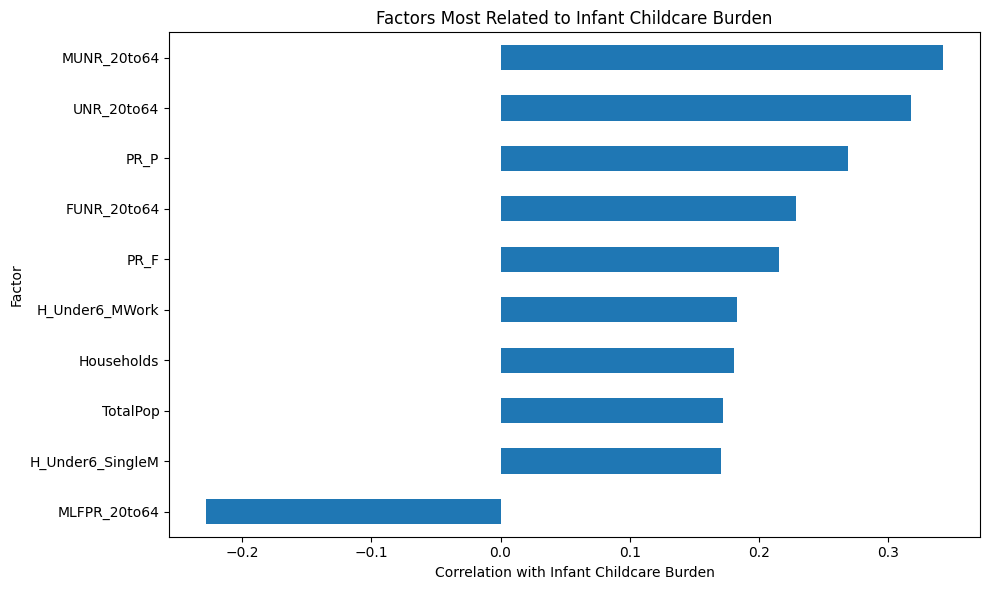

In [37]:
# Plot the top 10 factors most related to infant childcare burden
top_factors = correlations.head(10)

plt.figure(figsize=(10, 6))
top_factors.sort_values().plot(kind="barh")

plt.title("Factors Most Related to Infant Childcare Burden")
plt.xlabel("Correlation with Infant Childcare Burden")
plt.ylabel("Factor")
plt.tight_layout()
plt.show()

>>
This chart shows the factors that are most related to infant childcare affordability burden. The burden is measured as annual infant childcare cost as a percentage of median household income. The strongest positive relationships are with male unemployment rate, overall unemployment rate, poverty rate, and female unemployment rate. This means that counties with higher unemployment and poverty tend to have higher infant childcare burden. Household size, total population, and single-mother households also show some positive relationship with childcare burden. The male labor force participation rate has a negative relationship, which means that areas with higher male labor force participation tend to have lower infant childcare burden. 

## Comparison of Center-Based Care and Family Childcare, 2018

This visual compares average weekly childcare prices for center-based care and family childcare for infants, toddlers, and preschool-aged children. Side-by-side bars are used instead of stacked bars because these care settings are alternatives, not components of one combined childcare cost.

In [38]:
# Select the latest available study year
latest_year = int(analysis_df["StudyYear"].max())

# Keep only records from the latest year
latest_df = analysis_df[
    analysis_df["StudyYear"] == latest_year
].copy()

print("Latest year:", latest_year)
print("Number of records:", latest_df.shape[0])

Latest year: 2018
Number of records: 3142


,Age Group,Center-Based Care,Family Childcare,Price Difference,Center-Based Premium (%)
0,Infant,162.39,125.62,36.78,29.3
1,Toddler,145.96,118.51,27.45,23.2
2,Preschool,135.92,115.35,20.57,17.8


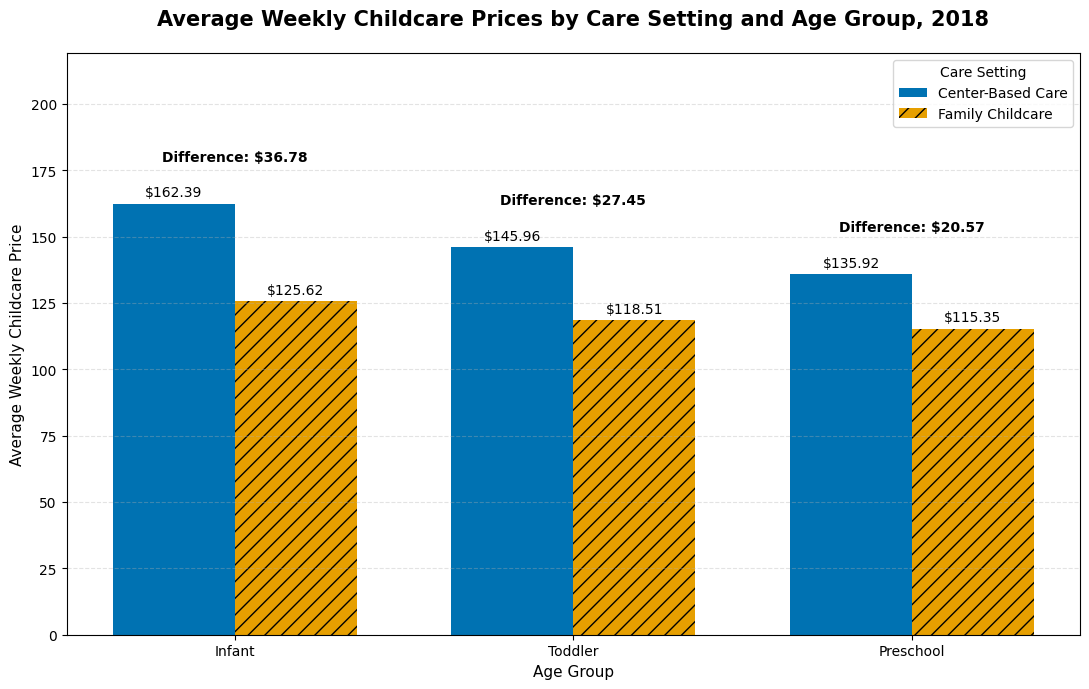

In [39]:
# Compare center-based care and family childcare in the latest study year

care_setting_comparison = pd.DataFrame({
    "Age Group": ["Infant", "Toddler", "Preschool"],
    "Center-Based Care": [
        latest_df["MCInfant"].mean(),
        latest_df["MCToddler"].mean(),
        latest_df["MCPreschool"].mean()
    ],
    "Family Childcare": [
        latest_df["MFCCInfant"].mean(),
        latest_df["MFCCToddler"].mean(),
        latest_df["MFCCPreschool"].mean()
    ]
})

# Calculate the dollar and percentage differences
care_setting_comparison["Price Difference"] = (
    care_setting_comparison["Center-Based Care"]
    - care_setting_comparison["Family Childcare"]
)

care_setting_comparison["Center-Based Premium (%)"] = (
    care_setting_comparison["Price Difference"]
    / care_setting_comparison["Family Childcare"]
    * 100
)

# Display the comparison table
display(
    care_setting_comparison.round({
        "Center-Based Care": 2,
        "Family Childcare": 2,
        "Price Difference": 2,
        "Center-Based Premium (%)": 1
    })
)

# Create side-by-side bar chart
age_groups = care_setting_comparison["Age Group"]
center_prices = care_setting_comparison["Center-Based Care"]
family_prices = care_setting_comparison["Family Childcare"]

x = np.arange(len(age_groups))
bar_width = 0.36

fig, ax = plt.subplots(figsize=(11, 7))

center_bars = ax.bar(
    x - bar_width / 2,
    center_prices,
    bar_width,
    label="Center-Based Care",
    color="#0072B2"
)

family_bars = ax.bar(
    x + bar_width / 2,
    family_prices,
    bar_width,
    label="Family Childcare",
    color="#E69F00",
    hatch="//"
)

# Add price labels above each bar
ax.bar_label(
    center_bars,
    labels=[f"${value:,.2f}" for value in center_prices],
    padding=3,
    fontsize=10
)

ax.bar_label(
    family_bars,
    labels=[f"${value:,.2f}" for value in family_prices],
    padding=3,
    fontsize=10
)

# Add the price difference above each age-group pair
for position, row in care_setting_comparison.iterrows():
    highest_price = max(
        row["Center-Based Care"],
        row["Family Childcare"]
    )

    ax.text(
        position,
        highest_price + 15,
        f"Difference: ${row['Price Difference']:,.2f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    f"Average Weekly Childcare Prices by Care Setting and Age Group, {latest_year}",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Age Group", fontsize=11)
ax.set_ylabel("Average Weekly Childcare Price", fontsize=11)

ax.set_xticks(x)
ax.set_xticklabels(age_groups)

ax.legend(title="Care Setting")
ax.grid(axis="y", linestyle="--", alpha=0.35)

# Leave room for the difference annotations
ax.set_ylim(0, max(center_prices.max(), family_prices.max()) * 1.35)

plt.tight_layout()
plt.show()

### Create a color-blind-friendly grouped bar chart

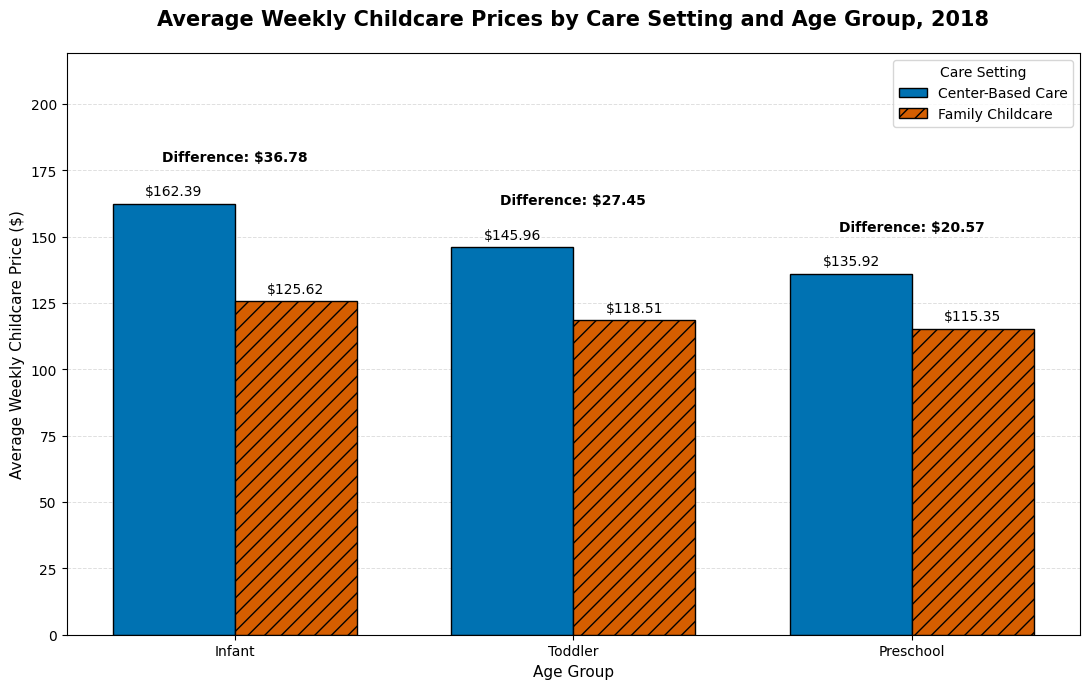

In [40]:
# Create a color-blind-friendly grouped bar chart

age_groups = care_setting_comparison["Age Group"]
center_prices = care_setting_comparison["Center-Based Care"]
family_prices = care_setting_comparison["Family Childcare"]

x = np.arange(len(age_groups))
bar_width = 0.36

fig, ax = plt.subplots(figsize=(11, 7))

# Okabe-Ito color-blind-friendly colors
center_color = "#0072B2"   # Blue
family_color = "#D55E00"   # Vermillion

center_bars = ax.bar(
    x - bar_width / 2,
    center_prices,
    bar_width,
    label="Center-Based Care",
    color=center_color,
    edgecolor="black",
    linewidth=1
)

family_bars = ax.bar(
    x + bar_width / 2,
    family_prices,
    bar_width,
    label="Family Childcare",
    color=family_color,
    edgecolor="black",
    linewidth=1,
    hatch="//"
)

# Add price labels
ax.bar_label(
    center_bars,
    labels=[f"${value:,.2f}" for value in center_prices],
    padding=4,
    fontsize=10
)

ax.bar_label(
    family_bars,
    labels=[f"${value:,.2f}" for value in family_prices],
    padding=4,
    fontsize=10
)

# Add the price difference above each pair
for position, row in care_setting_comparison.iterrows():
    highest_price = max(
        row["Center-Based Care"],
        row["Family Childcare"]
    )

    ax.text(
        position,
        highest_price + 15,
        f"Difference: ${row['Price Difference']:,.2f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    f"Average Weekly Childcare Prices by Care Setting and Age Group, {latest_year}",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Age Group", fontsize=11)
ax.set_ylabel("Average Weekly Childcare Price ($)", fontsize=11)

ax.set_xticks(x)
ax.set_xticklabels(age_groups)

ax.legend(
    title="Care Setting",
    frameon=True
)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.4
)

ax.set_axisbelow(True)

# Leave room for difference labels
ax.set_ylim(
    0,
    max(center_prices.max(), family_prices.max()) * 1.35
)

plt.tight_layout()
plt.show()

## Childcare Price Growth Compared with Household Income Growth

This visual compares the growth of center-based childcare prices with median household income from 2008 to 2018. Each measure is indexed to 100 in 2008 so that their percentage growth can be compared on the same scale. When childcare prices rise faster than household income, families may experience increasing financial pressure.

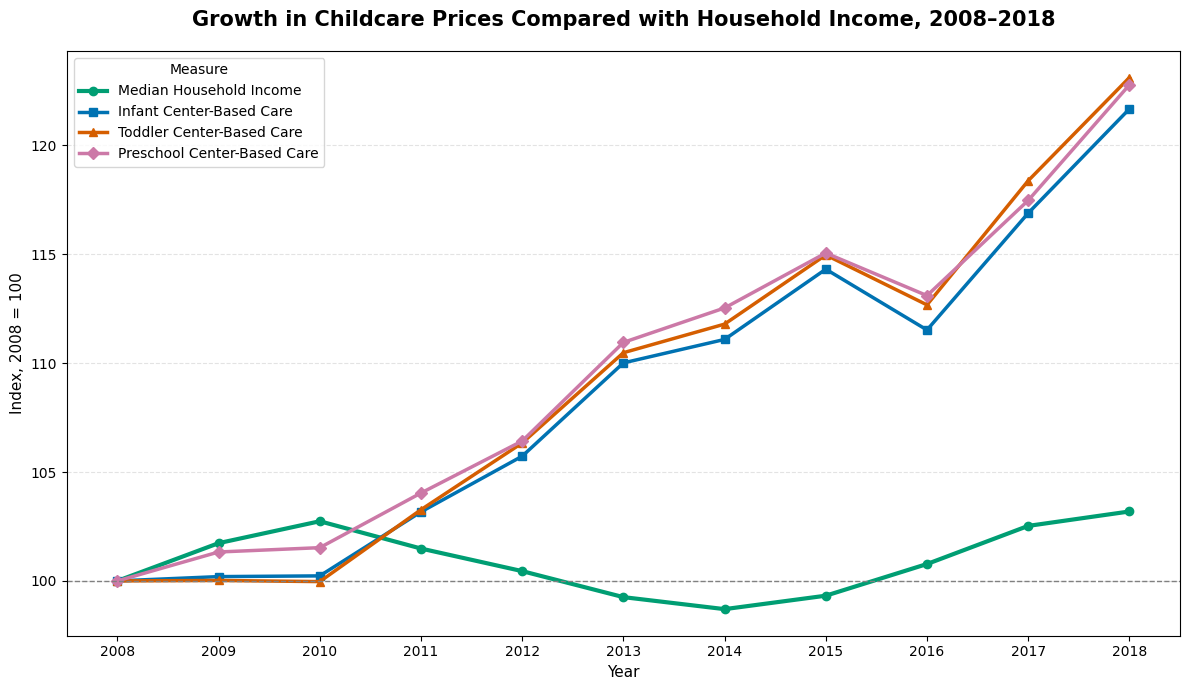

In [41]:
# Compare childcare price growth with household income growth

# Select the required columns and calculate yearly averages
wage_price_trend = (
    analysis_df.groupby("StudyYear", as_index=False)
    .agg(
        Median_Household_Income=("MHI_2018", "mean"),
        Infant_Care=("MCInfant", "mean"),
        Toddler_Care=("MCToddler", "mean"),
        Preschool_Care=("MCPreschool", "mean")
    )
    .sort_values("StudyYear")
)

# Remove rows with missing values
wage_price_trend = wage_price_trend.dropna().copy()

# Index every measure to 100 in the first year
first_year = wage_price_trend.iloc[0]

wage_price_trend["Income_Index"] = (
    wage_price_trend["Median_Household_Income"]
    / first_year["Median_Household_Income"]
    * 100
)

wage_price_trend["Infant_Index"] = (
    wage_price_trend["Infant_Care"]
    / first_year["Infant_Care"]
    * 100
)

wage_price_trend["Toddler_Index"] = (
    wage_price_trend["Toddler_Care"]
    / first_year["Toddler_Care"]
    * 100
)

wage_price_trend["Preschool_Index"] = (
    wage_price_trend["Preschool_Care"]
    / first_year["Preschool_Care"]
    * 100
)

# Create the visual
fig, ax = plt.subplots(figsize=(12, 7))

ax.plot(
    wage_price_trend["StudyYear"],
    wage_price_trend["Income_Index"],
    marker="o",
    linewidth=3,
    label="Median Household Income",
    color="#009E73"
)

ax.plot(
    wage_price_trend["StudyYear"],
    wage_price_trend["Infant_Index"],
    marker="s",
    linewidth=2.5,
    label="Infant Center-Based Care",
    color="#0072B2"
)

ax.plot(
    wage_price_trend["StudyYear"],
    wage_price_trend["Toddler_Index"],
    marker="^",
    linewidth=2.5,
    label="Toddler Center-Based Care",
    color="#D55E00"
)

ax.plot(
    wage_price_trend["StudyYear"],
    wage_price_trend["Preschool_Index"],
    marker="D",
    linewidth=2.5,
    label="Preschool Center-Based Care",
    color="#CC79A7"
)

# Reference line showing the starting level
ax.axhline(
    100,
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Growth in Childcare Prices Compared with Household Income, 2008–2018",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("Index, 2008 = 100", fontsize=11)

ax.set_xticks(wage_price_trend["StudyYear"])
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.legend(title="Measure", frameon=True)

ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

This chart compares the growth of center-based childcare prices with inflation-adjusted median household income from 2008 to 2018. Each measure is indexed to 100 in 2008, allowing the rates of growth to be compared directly. By 2018, infant, toddler, and preschool childcare prices had increased by approximately 22% to 23%, while median household income had increased by only about 3%. The widening gap shows that childcare costs grew much faster than household income during this period. This pattern suggests that stronger wage growth may be necessary for future families to keep pace with rising childcare expenses. However, the chart shows a relationship between income growth and childcare costs and does not prove that wage levels directly caused changes in childcare prices.

## Milestone 3 
We can also create an additional Tableau visual for the same data.

In [42]:
# Create a shorter Tableau-ready childcare dataset.
# Missing-data rule:
# - No fillna()
# - No replacement with zero, mean, median, or mode
# - Partial records are preserved
# - A row is removed only when every selected analytical field is missing


In [25]:
# File location
input_file = Path("nationaldatabaseofchildcareprices.xlsx")

# Read only the column names first
available_columns = pd.read_excel(
    input_file,
    nrows=0
).columns.tolist()

available_columns

['State_Name',
 'State_Abbreviation',
 'County_Name',
 'County_FIPS_Code',
 'StudyYear',
 'UNR_16',
 'FUNR_16',
 'MUNR_16',
 'UNR_20to64',
 'FUNR_20to64',
 'MUNR_20to64',
 'FLFPR_20to64',
 'FLFPR_20to64_Under6',
 'FLFPR_20to64_6to17',
 'FLFPR_20to64_Under6_6to17',
 'MLFPR_20to64',
 'PR_F',
 'PR_P',
 'MHI',
 'ME',
 'FME',
 'MME',
 'MHI_2018',
 'ME_2018',
 'FME_2018',
 'MME_2018',
 'TotalPop',
 'OneRace',
 'OneRace_W',
 'OneRace_B',
 'OneRace_I',
 'OneRace_A',
 'OneRace_H',
 'OneRace_Other',
 'TwoRaces',
 'Hispanic',
 'Households',
 'H_Under6_BothWork',
 'H_Under6_FWork',
 'H_Under6_MWork',
 'H_Under6_SingleM',
 'H_6to17_BothWork',
 'H_6to17_Fwork',
 'H_6to17_Mwork',
 'H_6to17_SingleM',
 'EMP_M',
 'MEMP_M',
 'FEMP_M',
 'EMP_Service',
 'MEMP_Service',
 'FEMP_Service',
 'EMP_Sales',
 'MEMP_Sales',
 'FEMP_Sales',
 'EMP_N',
 'MEMP_N',
 'FEMP_N',
 'EMP_P',
 'MEMP_P',
 'FEMP_P',
 'iUNR_16',
 'iFUNR_16',
 'iMUNR_16',
 'iUNR_20to64',
 'iFUNR_20to64',
 'iMUNR_20to64',
 'iFLFPR_20to64',
 'iFLFPR_2

In [26]:

# 1. IDENTIFIER COLUMNS
# ---------------------------------------------------

identifier_columns = [
    "State_Name",
    "State_Abbreviation",
    "County_Name",
    "County_FIPS_Code",
    "StudyYear"
]


# ---------------------------------------------------
# 2. CHILDCARE PRICE COLUMNS
# ---------------------------------------------------

basic_price_columns = [
    # Center-based childcare prices
    "MCInfant",
    "MCToddler",
    "MCPreschool",

    # Family childcare prices
    "MFCCInfant",
    "MFCCToddler",
    "MFCCPreschool"
]

# Keep the basic price columns and available 75th-percentile
# versions of those columns
price_columns = [
    column for column in available_columns
    if column in basic_price_columns
    or (
        "75" in column
        and any(
            price_name.lower() in column.lower()
            for price_name in basic_price_columns
        )
    )
]


# ---------------------------------------------------
# 3. RELEVANT CONTEXT COLUMNS
# ---------------------------------------------------

context_columns = [
    # Household income
    "MHI",
    "MHI_2022",

    # Labor-market conditions
    "UNR_20to64",
    "FUNR_20to64",
    "FLFPR_20to64",
    "FLFPR_20to64_Under6",

    # Poverty
    "PR_F",
    "PR_P",

    # Population and households
    "TotalPop",
    "totalpop",
    "Households",
    "households",

    # Family work structure
    "H_Under6_BothWork",
    "H_Under6_OneWork",
    "H_Under6_NoWork"
]




In [27]:
# COMBINE THE COLUMN LISTS
# ---------------------------------------------------

requested_columns = (
    identifier_columns
    + price_columns
    + context_columns
)

# Keep only columns that actually exist in the Excel file
selected_columns = [
    column for column in requested_columns
    if column in available_columns
]

# Remove duplicate column names while preserving order
selected_columns = list(dict.fromkeys(selected_columns))




In [28]:
# LOAD THE SHORTER DATASET
# ---------------------------------------------------

df = pd.read_excel(
    input_file,
    usecols=selected_columns
)

print("Original selected DataFrame shape:", df.shape)
print("Number of selected columns:", len(selected_columns))

print("\nSelected childcare-price columns:")
print(price_columns)

print("\nAll selected columns:")
print(selected_columns)

df.head()

Original selected DataFrame shape: (34567, 21)
Number of selected columns: 21

Selected childcare-price columns:
['MCInfant', 'MCToddler', 'MCPreschool', 'MFCCInfant', 'MFCCToddler', 'MFCCPreschool']

All selected columns:
['State_Name', 'State_Abbreviation', 'County_Name', 'County_FIPS_Code', 'StudyYear', 'MCInfant', 'MCToddler', 'MCPreschool', 'MFCCInfant', 'MFCCToddler', 'MFCCPreschool', 'MHI', 'UNR_20to64', 'FUNR_20to64', 'FLFPR_20to64', 'FLFPR_20to64_Under6', 'PR_F', 'PR_P', 'TotalPop', 'Households', 'H_Under6_BothWork']


,State_Name,State_Abbreviation,County_Name,County_FIPS_Code,StudyYear,UNR_20to64,FUNR_20to64,FLFPR_20to64,FLFPR_20to64_Under6,PR_F,...,MHI,TotalPop,Households,H_Under6_BothWork,MCInfant,MCToddler,MCPreschool,MFCCInfant,MFCCToddler,MFCCPreschool
0,Alabama,AL,Autauga County,1001,2008,4.6,3.5,68.9,66.9,8.5,...,50837.0,49744,18373,1543,104.95,104.95,85.92,83.45,83.45,81.40
1,Alabama,AL,Autauga County,1001,2009,4.8,4.6,70.8,63.7,7.5,...,51463.0,49584,18288,1475,105.11,105.11,87.59,87.39,87.39,85.68
2,Alabama,AL,Autauga County,1001,2010,5.1,4.6,71.3,67.0,7.5,...,53255.0,53155,19718,1569,105.28,105.28,89.26,91.33,91.33,89.96
3,Alabama,AL,Autauga County,1001,2011,6.2,6.3,70.2,66.5,7.4,...,53899.0,53944,19998,1695,105.45,105.45,90.93,95.28,95.28,94.25
4,Alabama,AL,Autauga County,1001,2012,6.7,6.4,70.6,67.1,7.4,...,53773.0,54590,19934,1714,105.61,105.61,92.60,99.22,99.22,98.53


In [29]:
# REMOVE ONLY COMPLETELY EMPTY ROWS
# ---------------------------------------------------------

# Keep the selected columns that exist in the DataFrame
tableau_columns = [
    column for column in selected_columns
    if column in df.columns
]

tableau_df = df[tableau_columns].copy()

rows_before = len(tableau_df)

# Create a temporary copy only for checking blank rows
blank_check = tableau_df.copy()

# Treat empty text and spaces as missing only during the check
text_columns = blank_check.select_dtypes(
    include=["object", "string"]
).columns

blank_check[text_columns] = blank_check[text_columns].replace(
    r"^\s*$",
    pd.NA,
    regex=True
)

# A row is removed only when every selected column is empty
completely_empty_rows = blank_check.isna().all(axis=1)

tableau_df = tableau_df.loc[
    ~completely_empty_rows
].copy()

tableau_df.reset_index(
    drop=True,
    inplace=True
)

rows_after = len(tableau_df)

print("Rows before cleaning:", rows_before)
print("Completely empty rows removed:", rows_before - rows_after)
print("Rows after cleaning:", rows_after)
print("Columns retained:", tableau_df.shape[1])
print("Final shape:", tableau_df.shape)

Rows before cleaning: 34567
Completely empty rows removed: 0
Rows after cleaning: 34567
Columns retained: 21
Final shape: (34567, 21)


In [30]:
tableau_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34567 entries, 0 to 34566
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   State_Name           34567 non-null  object 
 1   State_Abbreviation   34567 non-null  object 
 2   County_Name          34567 non-null  object 
 3   County_FIPS_Code     34567 non-null  int64  
 4   StudyYear            34567 non-null  int64  
 5   MCInfant             23593 non-null  float64
 6   MCToddler            23593 non-null  float64
 7   MCPreschool          23593 non-null  float64
 8   MFCCInfant           23383 non-null  float64
 9   MFCCToddler          23383 non-null  float64
 10  MFCCPreschool        23383 non-null  float64
 11  MHI                  34567 non-null  float64
 12  UNR_20to64           34567 non-null  float64
 13  FUNR_20to64          34567 non-null  float64
 14  FLFPR_20to64         34567 non-null  float64
 15  FLFPR_20to64_Under6  34567 non-null 

In [31]:

# Create output filenames
csv_file = "childcare_prices_tableau_ready.csv"
excel_file = "childcare_prices_tableau_ready.xlsx"

# Export as CSV
tableau_df.to_csv(
    csv_file,
    index=False
)

# Export as Excel
tableau_df.to_excel(
    excel_file,
    sheet_name="Tableau_Data",
    index=False
)

print("Files exported successfully!")


Files exported successfully!
